# 04 — All subsets: FD001, FD002, FD003, FD004

Until now we only used FD001, the easiest subset. Here we run our whole pipeline on all four C-MAPSS subsets and compare **Random Forest**, **LSTM** and **TransLSTM**.

The new difficulty: **FD002 and FD004 are flown in 6 different operating conditions** (altitude, Mach number, throttle). The sensor values depend strongly on the condition, so we must **normalize the sensors per operating condition** before the degradation becomes visible.

Steps:
1. Overview of the four subsets.
2. Identify the operating conditions from the 3 operational settings.
3. Show why per-condition normalization is needed.
4. Choose the sensors.
5. Handle test engines shorter than 30 cycles (padding).
6. Train all models on all subsets (3 seeds each) and compare them in a final table.

## 0. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Project root = parent of the "notebooks" folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import (
    FD001_SENSORS,
    SENSOR_COLUMNS,
    SUBSETS,
    add_operating_condition,
    add_train_rul,
    apply_condition_scaler,
    fit_condition_scaler,
    load_cmapss,
    split_by_engine,
)
from src.metrics import nasa_score, rmse
from src.models import LSTMModel, TransLSTM
from src.sequences import make_last_windows, make_windows
from src.training import predict, set_seed, train_model

FIG_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

RUL_CAP = 125
WINDOW_SIZE = 30
SPLIT_SEED = 42        # same train/validation engines for every model and seed
SEEDS = [0, 1, 2]      # 3 seeds per model

## 1. The four subsets

All loading code is in `src/data.py`; `load_cmapss(subset)` works for any of the four subsets.

| Subset | Operating conditions | Fault modes |
|---|---|---|
| FD001 | 1 | 1 (HPC degradation) |
| FD002 | 6 | 1 (HPC degradation) |
| FD003 | 1 | 2 (HPC and fan degradation) |
| FD004 | 6 | 2 (HPC and fan degradation) |

(Fault modes are from the dataset documentation, Saxena et al. 2008.) Let's count engines and test trajectory lengths.

In [2]:
overview_rows = []
for subset in SUBSETS:
    train, test, test_rul = load_cmapss(subset)
    test_lengths = test.groupby("unit")["cycle"].max()
    overview_rows.append({
        "subset": subset,
        "train engines": train["unit"].nunique(),
        "train rows": len(train),
        "test engines": test["unit"].nunique(),
        "shortest test engine (cycles)": test_lengths.min(),
        f"test engines < {WINDOW_SIZE} cycles": (test_lengths < WINDOW_SIZE).sum(),
        "test engines with true RUL > 125": (test_rul["true_rul"] > RUL_CAP).sum(),
    })

pd.DataFrame(overview_rows).set_index("subset")

,train engines,train rows,test engines,shortest test engine (cycles),test engines < 30 cycles,test engines with true RUL > 125
subset,,,,,,
FD001,100,20631,100,31,0,11
FD002,260,53759,259,21,6,57
FD003,100,24720,100,38,0,15
FD004,249,61249,248,19,11,67


FD002 and FD004 are about 2.5 times larger than FD001/FD003, and they contain test engines **shorter than our 30-cycle window** (section 5). They also have many more test engines with a true RUL above the cap of 125.

## 2. Identify the operating conditions

The 3 operational settings are altitude (`setting_1`, in thousands of feet), Mach number (`setting_2`) and throttle resolver angle (`setting_3`). In FD002 they only take **6 combinations**, plus a tiny measurement noise. A scatter plot shows the clusters:

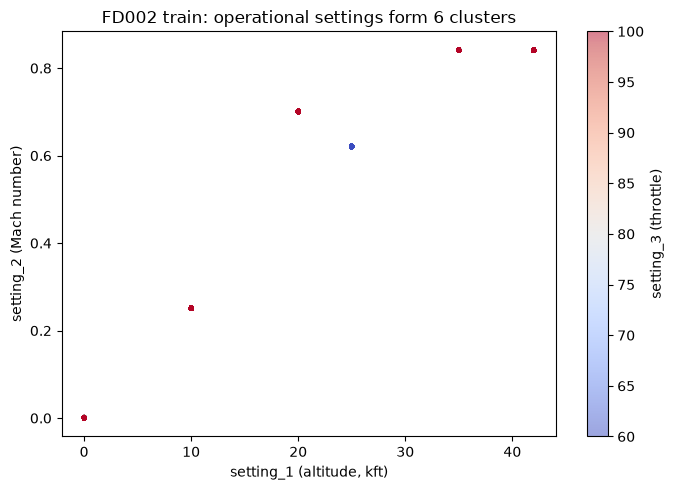

In [3]:
train_fd002, _, _ = load_cmapss("FD002")

plt.figure(figsize=(7, 5))
plt.scatter(train_fd002["setting_1"], train_fd002["setting_2"], c=train_fd002["setting_3"],
            cmap="coolwarm", s=5, alpha=0.5)
plt.colorbar(label="setting_3 (throttle)")
plt.xlabel("setting_1 (altitude, kft)")
plt.ylabel("setting_2 (Mach number)")
plt.title("FD002 train: operational settings form 6 clusters")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_operating_conditions_fd002.png", dpi=150)
plt.show()

Because the clusters are so well separated, we do not need a clustering algorithm: **rounding** the settings removes the noise (`setting_1` to 0 decimals, `setting_2` to 2 decimals, `setting_3` to 0 decimals). The combination of the 3 rounded values names the condition, e.g. `42_0.84_100`. This is `add_operating_condition` in `src/data.py`.

In [4]:
for subset in SUBSETS:
    train, test, _ = load_cmapss(subset)
    train = add_operating_condition(train)
    test = add_operating_condition(test)
    # Every condition of the test set must also exist in training
    test_conditions_known = set(test["condition"]) <= set(train["condition"])
    print(f"{subset}: {train['condition'].nunique()} condition(s) "
          f"{sorted(train['condition'].unique())} | all test conditions seen in train: {test_conditions_known}")

FD001: 1 condition(s) ['0_0_100'] | all test conditions seen in train: True


FD002: 6 condition(s) ['0_0_100', '10_0.25_100', '20_0.7_100', '25_0.62_60', '35_0.84_100', '42_0.84_100'] | all test conditions seen in train: True


FD003: 1 condition(s) ['0_0_100'] | all test conditions seen in train: True


FD004: 6 condition(s) ['0_0_100', '10_0.25_100', '20_0.7_100', '25_0.62_60', '35_0.84_100', '42_0.84_100'] | all test conditions seen in train: True


## 3. Why we normalize per operating condition

Below we follow one sensor (`sensor_4`, the LPT outlet temperature) for one FD002 engine.

- **Left (raw values):** the value jumps between 6 levels, one per operating condition (colours). These jumps (up to ~380 degrees between conditions) are much larger than the slow drift caused by degradation (about 30 degrees over the whole life), so the degradation is hidden.
- **Right (normalized per condition):** for each condition we subtract its mean and divide by its standard deviation, both computed on the training engines. Now 0 means "normal for this flight condition", the jumps disappear and the **upward degradation trend** becomes visible (black line = moving average over 15 cycles).

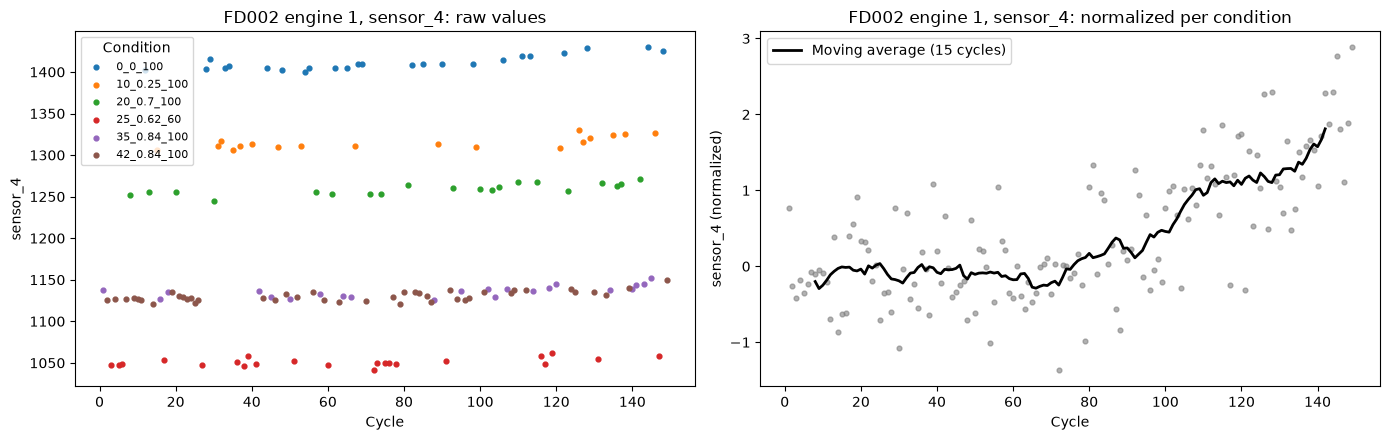

In [5]:
train_fd002 = add_operating_condition(add_train_rul(train_fd002))
means, stds = fit_condition_scaler(train_fd002, FD001_SENSORS)
train_fd002_norm = apply_condition_scaler(train_fd002, FD001_SENSORS, means, stds)

sensor = "sensor_4"
engine_raw = train_fd002[train_fd002["unit"] == 1]
engine_norm = train_fd002_norm[train_fd002_norm["unit"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for condition in sorted(engine_raw["condition"].unique()):
    rows = engine_raw["condition"] == condition
    axes[0].scatter(engine_raw.loc[rows, "cycle"], engine_raw.loc[rows, sensor], s=12, label=condition)
axes[0].set_title(f"FD002 engine 1, {sensor}: raw values")
axes[0].set_xlabel("Cycle")
axes[0].set_ylabel(sensor)
axes[0].legend(title="Condition", fontsize=8)

axes[1].scatter(engine_norm["cycle"], engine_norm[sensor], s=12, color="grey", alpha=0.6)
moving_average = engine_norm[sensor].rolling(15, center=True).mean()
axes[1].plot(engine_norm["cycle"], moving_average, color="black", linewidth=2, label="Moving average (15 cycles)")
axes[1].set_title(f"FD002 engine 1, {sensor}: normalized per condition")
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel(f"{sensor} (normalized)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "04_condition_normalization_fd002.png", dpi=150)
plt.show()

In this illustration the scaler was fitted on all FD002 training engines. In the real pipeline (section 6) it is fitted **only on the training engines of the split**, then applied to validation and test engines, to avoid data leakage.

For FD001 and FD003 there is only one condition, so per-condition normalization is the same as the ordinary `StandardScaler` used in `03`. We can therefore use **one pipeline for all four subsets**.

## 4. Sensor selection

In `01_eda` we removed 7 sensors from FD001 because they were constant. In FD002/FD004 *no* raw sensor is constant (they all change with the condition), so we check the number of distinct values **within each condition**. The table shows the maximum over the conditions, for the sensors that have at most 10 distinct values.

In [6]:
rows = {}
for subset in SUBSETS:
    train, _, _ = load_cmapss(subset)
    train = add_operating_condition(train)
    n_unique = train.groupby("condition")[SENSOR_COLUMNS].nunique().max()
    rows[subset] = n_unique

table = pd.DataFrame(rows)
# Keep only the sensors with at most 10 distinct values in at least one subset
table = table[(table <= 10).any(axis=1)]
# Show "> 10" instead of large numbers, to make the table easier to read
table.astype(object).where(table <= 10, "> 10")

,FD001,FD002,FD003,FD004
sensor_1,1,1,1,1
sensor_5,1,1,1,1
sensor_6,2,3,> 10,> 10
sensor_10,1,2,4,6
sensor_16,1,2,1,2
sensor_18,1,1,1,1
sensor_19,1,1,1,1


In every subset, sensors 1, 5, 18 and 19 are constant within a condition, and sensors 6, 10 and 16 take at most 6 distinct values: they carry (almost) no degradation information. So we keep **the same 14 sensors as for FD001** (`FD001_SENSORS`) for all subsets. Using the same inputs everywhere also keeps the comparison between subsets fair.

## 5. Test engines shorter than 30 cycles

Our sequence models need **exactly 30 cycles** as input. In FD002 and FD004 some test engines have fewer cycles (the shortest has 19). We still have to predict their RUL: the test set (and a real fleet) must be fully covered, so we cannot just drop them.

Options:
- **Use a shorter window for these engines:** not possible, the network is built for a fixed length of 30.
- **Pad with zeros:** after normalization, 0 means "average value for this condition", an artificial reading that never happened.
- **Pad by repeating the first recorded cycle** ✅ (our choice). These engines were recorded only for a short time, so they are early in their life and still healthy. Before the first recorded cycle, the engine was in (almost) the same healthy state, so repeating the first reading is a realistic guess of what the missing cycles looked like.

`make_last_windows` in `src/sequences.py` does this padding. Let's look at the true RUL of these short engines:

In [7]:
for subset in SUBSETS:
    _, test, test_rul = load_cmapss(subset)
    test_lengths = test.groupby("unit")["cycle"].max()
    short_units = test_lengths[test_lengths < WINDOW_SIZE].index
    if len(short_units) == 0:
        print(f"{subset}: no test engine shorter than {WINDOW_SIZE} cycles")
        continue
    short = test_rul[test_rul["unit"].isin(short_units)].copy()
    short["recorded cycles"] = test_lengths.loc[short_units].values
    print(f"{subset}: {len(short)} short test engines")
    display(short.set_index("unit").T)

FD001: no test engine shorter than 30 cycles


FD002: 6 short test engines


unit,28,59,83,122,201,223
true_rul,138,178,146,145,111,151
recorded cycles,23,22,21,29,25,29


FD003: no test engine shorter than 30 cycles


FD004: 11 short test engines


unit,10,19,28,125,141,156,164,204,229,239,246
true_rul,162,194,124,184,130,133,174,151,120,166,194
recorded cycles,23,24,20,21,19,28,29,19,20,28,29


All 17 short engines have a true RUL between 111 and 194 cycles, which supports "early in life, still healthy": the padded cycles are copies of a healthy reading, and for these engines the model should predict a value close to the cap of 125.

## 6. The pipeline

For each subset we do exactly what we did for FD001 in `02` and `03`:

1. Load, compute the RUL and **cap it at 125**.
2. Add the operating condition.
3. **Split by engine:** 80% training engines, 20% validation engines (same split seed 42 for all models).
4. **Normalize per condition**, fitting the means/stds on the training engines only.
5. Build **windows of 30 cycles** for train/validation, and the **last window** (padded if needed) for each test engine.

Then we train:
- **Random Forest** (as in `02`): one cycle per sample, normalized sensors, 100 trees.
- **LSTM** and **TransLSTM** (as in `03`, same architectures).

Each model is trained with **3 seeds** (0, 1, 2). The seed changes the random parts of the model (initial weights and batch order for the networks, bootstrap samples for the Random Forest); the train/validation split stays the same.

### Changes to keep it fast on a laptop CPU

FD002 and FD004 have ~2.5× more data than FD001, and we train 3 models × 3 seeds × 4 subsets. To keep the total time reasonable we changed two settings compared to `03`:
- **Training windows with stride 2:** we keep every 2nd training window. Two neighbouring windows share 29 of their 30 cycles, so we lose almost no information but halve the training time. The window that ends at failure is always kept. Validation and test windows are not reduced.
- **Early-stopping patience 5** (instead of 10), with at most 30 epochs. In `03` the best epochs were 3 and 8, so 5 epochs without improvement is enough to detect the end of learning.

Because of these changes (and the different seeds), the FD001 numbers here can differ slightly from `03`.

In [8]:
TRAIN_STRIDE = 2
MAX_EPOCHS = 30
PATIENCE = 5


def prepare_subset(subset):
    """Load one subset and return everything needed to train and evaluate the models."""
    train, test, test_rul = load_cmapss(subset)

    # 1. RUL capped at 125
    train = add_train_rul(train)
    train["RUL"] = np.minimum(train["RUL"], RUL_CAP)

    # 2. Operating condition of every row
    train = add_operating_condition(train)
    test = add_operating_condition(test)

    # 3. Split by engine
    train_part, val_part = split_by_engine(train, val_fraction=0.2, seed=SPLIT_SEED)

    # 4. Per-condition normalization, fitted on the training engines only
    means, stds = fit_condition_scaler(train_part, FD001_SENSORS)
    train_part = apply_condition_scaler(train_part, FD001_SENSORS, means, stds)
    val_part = apply_condition_scaler(val_part, FD001_SENSORS, means, stds)
    test = apply_condition_scaler(test, FD001_SENSORS, means, stds)

    # 5. Windows (padding of short test engines happens inside make_last_windows)
    X_train, y_train = make_windows(train_part, FD001_SENSORS, WINDOW_SIZE, stride=TRAIN_STRIDE)
    X_val, y_val = make_windows(val_part, FD001_SENSORS, WINDOW_SIZE)
    X_test, test_units = make_last_windows(test, FD001_SENSORS, WINDOW_SIZE)
    assert (test_units == test_rul["unit"].values).all()

    # Last recorded cycle of each test engine, for the Random Forest
    test_last_cycle = test.groupby("unit").tail(1).sort_values("unit")

    return {
        "train_part": train_part,
        "X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test,
        "X_test_rf": test_last_cycle[FD001_SENSORS],
        "y_test": test_rul["true_rul"].values,
    }


def run_random_forest(data, seed):
    """Train a Random Forest on single cycles and return its test predictions."""
    rf = RandomForestRegressor(n_estimators=100, random_state=seed, n_jobs=-1)
    rf.fit(data["train_part"][FD001_SENSORS], data["train_part"]["RUL"])
    return rf.predict(data["X_test_rf"])


def run_neural_model(model_name, data, seed):
    """Train an LSTM or TransLSTM with early stopping and return its test predictions."""
    set_seed(seed)  # same initial weights for the same seed
    n_features = len(FD001_SENSORS)
    if model_name == "LSTM":
        model = LSTMModel(n_features=n_features)
    else:
        model = TransLSTM(n_features=n_features, window_size=WINDOW_SIZE)

    model, history = train_model(
        model,
        data["X_train"], data["y_train"] / RUL_CAP,   # targets scaled to [0, 1]
        data["X_val"], data["y_val"] / RUL_CAP,
        max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=seed, verbose=False,
    )
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    return predict(model, data["X_test"]) * RUL_CAP, best_epoch

## 7. Train all models on all subsets

This is the long cell: **about 47 minutes** on our 8-thread CPU (36 runs; the TransLSTM on FD002/FD004 takes 3–5 minutes per run).

**Saved progress:** after each run, the result is appended to `results/metrics/04_all_runs.csv`. If that file already exists, runs that are already in it are **skipped** and their saved result is printed with "(saved)". So you can stop the notebook and continue later, and re-running the notebook only takes seconds. Delete the file to retrain everything.

In [9]:
RUNS_FILE = METRICS_DIR / "04_all_runs.csv"
MODEL_NAMES = ["Random Forest", "LSTM", "TransLSTM"]

if RUNS_FILE.exists():
    runs = pd.read_csv(RUNS_FILE)
else:
    runs = pd.DataFrame(columns=["subset", "model", "seed", "test_RMSE", "test_NASA_score",
                                 "best_epoch", "train_seconds"])

total_start = time.time()
for subset in SUBSETS:
    data = None  # prepared only if at least one run of this subset is missing
    for model_name in MODEL_NAMES:
        for seed in SEEDS:
            saved = runs[(runs["subset"] == subset) & (runs["model"] == model_name)
                         & (runs["seed"] == seed)]
            if len(saved) > 0:
                row = saved.iloc[0]
                print(f"  {subset} {model_name:13s} seed {seed}: RMSE {row['test_RMSE']:6.2f} | "
                      f"NASA {row['test_NASA_score']:9.0f} | {row['train_seconds']:5.0f} s (saved)")
                continue
            if data is None:
                data = prepare_subset(subset)
                print(f"{subset}: {len(data['X_train'])} train windows, "
                      f"{len(data['X_val'])} validation windows, {len(data['X_test'])} test engines")

            start = time.time()
            if model_name == "Random Forest":
                test_pred = run_random_forest(data, seed)
                best_epoch = np.nan
            else:
                test_pred, best_epoch = run_neural_model(model_name, data, seed)
            seconds = time.time() - start

            new_row = {
                "subset": subset,
                "model": model_name,
                "seed": seed,
                "test_RMSE": rmse(data["y_test"], test_pred),
                "test_NASA_score": nasa_score(data["y_test"], test_pred),
                "best_epoch": best_epoch,
                "train_seconds": seconds,
            }
            runs = pd.concat([runs, pd.DataFrame([new_row])], ignore_index=True)
            runs.to_csv(RUNS_FILE, index=False)  # save progress after every run
            print(f"  {subset} {model_name:13s} seed {seed}: RMSE {new_row['test_RMSE']:6.2f} | "
                  f"NASA {new_row['test_NASA_score']:9.0f} | {seconds:5.0f} s")

print(f"Total time for this cell: {(time.time() - total_start) / 60:.1f} min")

  FD001 Random Forest seed 0: RMSE  17.62 | NASA       904 |     1 s (saved)
  FD001 Random Forest seed 1: RMSE  17.83 | NASA       934 |     1 s (saved)
  FD001 Random Forest seed 2: RMSE  17.69 | NASA       791 |     2 s (saved)
  FD001 LSTM          seed 0: RMSE  15.82 | NASA       458 |    27 s (saved)
  FD001 LSTM          seed 1: RMSE  15.96 | NASA       470 |    28 s (saved)
  FD001 LSTM          seed 2: RMSE  16.04 | NASA       493 |    48 s (saved)
  FD001 TransLSTM     seed 0: RMSE  16.03 | NASA       534 |    70 s (saved)
  FD001 TransLSTM     seed 1: RMSE  15.20 | NASA       395 |    80 s (saved)
  FD001 TransLSTM     seed 2: RMSE  16.26 | NASA       505 |   107 s (saved)
  FD002 Random Forest seed 0: RMSE  29.85 | NASA     15977 |     5 s (saved)
  FD002 Random Forest seed 1: RMSE  29.91 | NASA     15263 |     5 s (saved)
  FD002 Random Forest seed 2: RMSE  30.01 | NASA     15857 |     5 s (saved)
  FD002 LSTM          seed 0: RMSE  27.81 | NASA     12679 |   113 s (saved)

## 8. Final results: mean ± standard deviation over 3 seeds

The test RMSE and NASA score are computed on **all test engines** of each subset, against the **true (uncapped)** RUL.

*Note:* the NASA score is a **sum** over engines, and FD002/FD004 have ~2.5× more test engines than FD001/FD003, so NASA scores should only be compared **within** a subset, not between subsets.

In [10]:
runs = pd.read_csv(RUNS_FILE)

summary = runs.groupby(["subset", "model"]).agg(
    RMSE_mean=("test_RMSE", "mean"),
    RMSE_std=("test_RMSE", "std"),
    NASA_mean=("test_NASA_score", "mean"),
    NASA_std=("test_NASA_score", "std"),
).reset_index()
summary.to_csv(METRICS_DIR / "04_summary.csv", index=False)

# Readable "mean ± std" strings, one row per model, one column per subset
summary["RMSE"] = summary["RMSE_mean"].map("{:.2f}".format) + " ± " + summary["RMSE_std"].map("{:.2f}".format)
summary["NASA score"] = summary["NASA_mean"].map("{:.0f}".format) + " ± " + summary["NASA_std"].map("{:.0f}".format)

print("Test RMSE (cycles), mean ± std over 3 seeds")
display(summary.pivot(index="model", columns="subset", values="RMSE").loc[MODEL_NAMES])

print("Test NASA score, mean ± std over 3 seeds")
display(summary.pivot(index="model", columns="subset", values="NASA score").loc[MODEL_NAMES])

Test RMSE (cycles), mean ± std over 3 seeds


subset,FD001,FD002,FD003,FD004
model,,,,
Random Forest,17.72 ± 0.11,29.92 ± 0.08,21.42 ± 0.05,31.91 ± 0.08
LSTM,15.94 ± 0.12,27.79 ± 0.14,16.62 ± 0.82,26.78 ± 0.41
TransLSTM,15.83 ± 0.56,27.86 ± 0.96,17.05 ± 0.52,27.01 ± 0.53


Test NASA score, mean ± std over 3 seeds


subset,FD001,FD002,FD003,FD004
model,,,,
Random Forest,877 ± 75,15699 ± 382,2230 ± 38,10038 ± 380
LSTM,474 ± 18,12926 ± 650,993 ± 70,5115 ± 265
TransLSTM,478 ± 73,12781 ± 3812,615 ± 145,5137 ± 803


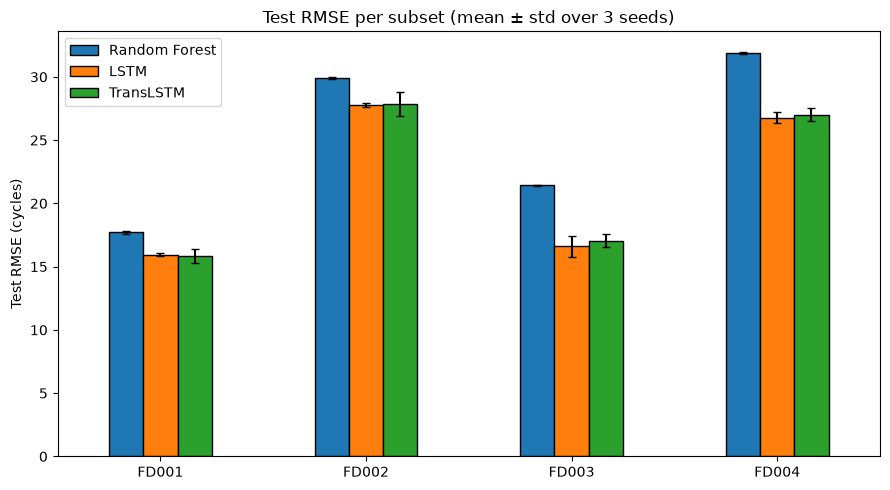

In [11]:
# Bar chart of test RMSE with the standard deviation as error bars
rmse_mean = summary.pivot(index="subset", columns="model", values="RMSE_mean")[MODEL_NAMES]
rmse_std = summary.pivot(index="subset", columns="model", values="RMSE_std")[MODEL_NAMES]

rmse_mean.plot(kind="bar", yerr=rmse_std, capsize=3, figsize=(9, 5), edgecolor="black")
plt.ylabel("Test RMSE (cycles)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.title("Test RMSE per subset (mean ± std over 3 seeds)")
plt.legend(title="")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_rmse_all_subsets.png", dpi=150)
plt.show()

In [12]:
# Training time and best epoch, to see the cost of each model
runs.groupby(["subset", "model"])[["train_seconds", "best_epoch"]].mean().round(1)

train_seconds  best_epoch
subset model                                   
FD001  LSTM                    34.1        19.7
       Random Forest            1.5         NaN
       TransLSTM               85.5         7.0
FD002  LSTM                   111.1        10.0
       Random Forest            5.2         NaN
       TransLSTM              227.6         4.3
FD003  LSTM                    48.7        19.7
       Random Forest            2.2         NaN
       TransLSTM              116.0         8.7
FD004  LSTM                    95.1        13.7
       Random Forest            7.1         NaN
       TransLSTM              209.7         5.3

### How much of the error comes from the RUL cap?

Our models never predict much more than 125, but we compare them to the **true, uncapped** test RUL. So an engine with a true RUL of 190 gives an error of at least 65 cycles, however good the model is.

To measure this effect alone, we score a "perfect capped model" that predicts exactly `min(true RUL, 125)` for every test engine. Its error comes **only** from the cap: no real model with our cap can do better on those engines.

In [13]:
cap_rows = []
for subset in SUBSETS:
    _, _, test_rul = load_cmapss(subset)
    y_true = test_rul["true_rul"].values
    perfect_capped = np.minimum(y_true, RUL_CAP)
    cap_rows.append({
        "subset": subset,
        "test engines with true RUL > 125": (y_true > RUL_CAP).sum(),
        "max true RUL": y_true.max(),
        "RMSE of perfect capped model": rmse(y_true, perfect_capped),
        "NASA of perfect capped model": nasa_score(y_true, perfect_capped),
    })

pd.DataFrame(cap_rows).set_index("subset").round(2)

,test engines with true RUL > 125,max true RUL,RMSE of perfect capped model,NASA of perfect capped model
subset,,,,
FD001,11,145,3.74,14.58
FD002,57,194,18.32,2010.35
FD003,15,145,4.71,22.66
FD004,67,195,19.53,2130.34


## 9. Discussion

1. **Sequence models beat the Random Forest on every subset**, with every seed. The gain is largest on FD003 (RMSE 21.4 → ~16.6–17.1) and FD004 (31.9 → ~27). The NASA score also falls on every subset, often by half.

2. **LSTM vs TransLSTM: no clear winner.** Their mean RMSEs are within about 0.5 cycles on every subset, and the seed-to-seed standard deviations overlap. The TransLSTM has the better mean NASA score on FD003 (615 vs 993), but it is also **less stable** (larger std on FD001–FD003) and takes about **2× longer** to train. On FD002, one TransLSTM seed stopped at epoch 2, which shows how sensitive it is.

3. **FD002 and FD004 are much harder** (RMSE ~27 vs ~16), and a large part of this is the evaluation, not the models. These subsets have many test engines with a true RUL above 125 (57 and 67), up to ~195 cycles. The table above shows that even a *perfect* capped model would get an RMSE of **18.3 (FD002) and 19.5 (FD004)** against the uncapped truth, versus only 3.7 and 4.7 on FD001 and FD003. Many papers also cap the *test* RUL, which removes this error, so their FD002/FD004 numbers are not directly comparable to ours.

4. **Per-condition normalization works.** Without it, the 6 operating conditions would hide the degradation completely (section 3). With it, the same pipeline and models run unchanged on all four subsets.

5. **Two fault modes (FD003, FD004) cost little** compared to the effect of multiple conditions: FD003 is only ~1 cycle worse than FD001 for the sequence models.

**Limitations.** Each result uses one train/validation split (seed 42) and 3 model seeds. To save time we used training windows with stride 2 and early-stopping patience 5; one LSTM run (FD003, seed 1) found its best epoch at 28, close to the 30-epoch limit, so it might improve slightly with more epochs.